In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
np.random.seed(42)

n = 500

data = pd.DataFrame({
    "Gender": np.random.choice(["Male", "Female"], n),
    "Married": np.random.choice(["Yes", "No"], n),
    "Education": np.random.choice(["Graduate", "Not Graduate"], n),
    "Self_Employed": np.random.choice(["Yes", "No"], n),
    "ApplicantIncome": np.random.randint(1500, 15000, n),
    "CoapplicantIncome": np.random.randint(0, 8000, n),
    "LoanAmount": np.random.randint(50, 500, n),
    "Credit_History": np.random.choice([0, 1], n, p=[0.25, 0.75]),
    "Property_Area": np.random.choice(
        ["Urban", "Semiurban", "Rural"], n
    )
})

# Sample target variable for demonstration
data["Loan_Status"] = np.where(
    (data["Credit_History"] == 1) &
    (data["ApplicantIncome"] + data["CoapplicantIncome"] > 5000) &
    (data["LoanAmount"] < 400),
    "Approved",
    "Rejected"
)

data.head()

,Gender,Married,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Credit_History,Property_Area,Loan_Status
0,Male,Yes,Not Graduate,Yes,9482,7537,170,0,Semiurban,Rejected
1,Female,Yes,Graduate,No,5607,715,174,1,Rural,Approved
2,Male,Yes,Graduate,No,2841,5383,219,1,Rural,Approved
3,Male,No,Graduate,Yes,13355,3911,121,1,Urban,Approved
4,Male,Yes,Graduate,Yes,9907,1713,201,1,Semiurban,Approved


In [4]:
print("Dataset shape:", data.shape)

display(data.head(10))

print("\nDataset information:")
data.info()

print("\nMissing values:")
print(data.isnull().sum())

print("\nLoan status distribution:")
print(data["Loan_Status"].value_counts())

Dataset shape: (500, 10)


,Gender,Married,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Credit_History,Property_Area,Loan_Status
0,Male,Yes,Not Graduate,Yes,9482,7537,170,0,Semiurban,Rejected
1,Female,Yes,Graduate,No,5607,715,174,1,Rural,Approved
2,Male,Yes,Graduate,No,2841,5383,219,1,Rural,Approved
3,Male,No,Graduate,Yes,13355,3911,121,1,Urban,Approved
4,Male,Yes,Graduate,Yes,9907,1713,201,1,Semiurban,Approved
5,Female,Yes,Graduate,Yes,1838,5979,257,1,Semiurban,Approved
6,Male,No,Not Graduate,No,7395,3389,98,1,Semiurban,Approved
7,Male,Yes,Graduate,No,13754,1107,203,1,Rural,Approved
8,Male,No,Not Graduate,No,4208,5437,396,1,Semiurban,Approved
9,Female,No,Not Graduate,No,12844,4206,342,1,Urban,Approved



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Gender             500 non-null    object
 1   Married            500 non-null    object
 2   Education          500 non-null    object
 3   Self_Employed      500 non-null    object
 4   ApplicantIncome    500 non-null    int32 
 5   CoapplicantIncome  500 non-null    int32 
 6   LoanAmount         500 non-null    int32 
 7   Credit_History     500 non-null    int64 
 8   Property_Area      500 non-null    object
 9   Loan_Status        500 non-null    object
dtypes: int32(3), int64(1), object(6)
memory usage: 33.3+ KB

Missing values:
Gender               0
Married              0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Credit_History       0
Property_Area        0
Loan_Status          0
d

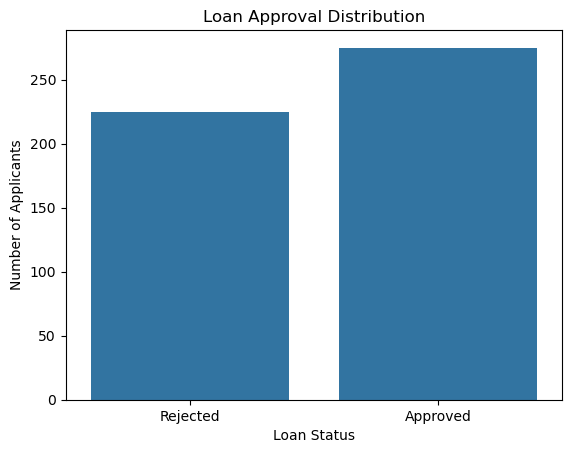

In [5]:
sns.countplot(data=data, x="Loan_Status")
plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.show()

In [6]:
X = data.drop("Loan_Status", axis=1)
y = data["Loan_Status"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (500, 9)
Target: (500,)


In [7]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numerical_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [8]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 99.00%

Classification Report:

              precision    recall  f1-score   support

    Approved       0.98      1.00      0.99        55
    Rejected       1.00      0.98      0.99        45

    accuracy                           0.99       100
   macro avg       0.99      0.99      0.99       100
weighted avg       0.99      0.99      0.99       100

